In [1]:
#import the necessary libraries 

#matplotlib
import matplotlib.pyplot as plot
import matplotlib.image as img

#numpy
import numpy as np

#scipy
import scipy
from scipy import ndimage

#scikit image
from skimage import io
import matplotlib.image as mpimg
from skimage.transform import rescale, resize, downscale_local_mean
from skimage.color import rgb2gray, rgb2hsv
from skimage.filters import threshold_otsu
from PIL import Image
import cv2
from skimage import measure
import skimage as image_tool
from skimage.measure import label, regionprops, regionprops_table
from skimage.segmentation import clear_border
import matplotlib.image as mpimg


import cv2
import numpy as np
from PIL import Image
from skimage.morphology import opening, disk


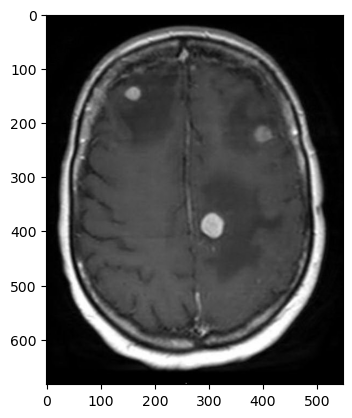

In [2]:
#Reading the Mermaid Image
img = img.imread('brain_tumors.jpg')

#plotting the given image
plot.imshow(img)

The given image appears to be an MRI scan of a human brain. The scan is detailed, showing various structures of the brain with high contrast. The dark background enhances the visibility of the lighter cerebral tissues and any abnormalities, such as the existence of any tumors. In our case, we can observe several bright spots that indicate the existence of 3 tumors in different areas of the brain more specifically, two in the right lobe and one in the left lobe of the brain. 
Such images are typically used in the medical field for diagnostic purposes, allowing healthcare professionals to non-invasively examine the inner workings of the brain.


##  A) Manual Thresholding Value

In [3]:
import cv2

#coverting the original image to grayscale 
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# blurring the gray image to remove any noise
blurred = cv2.GaussianBlur(gray, (7, 7), 0)

#applying the threshold (with manual value of 100)
ret, thresh_binary = cv2.threshold(blurred, 100, 255, cv2.THRESH_BINARY)

After playing around with the threshold values we found out that the best results regarding the appearance of the 3 tumors was a threshhold value = 100. 
It's important to mention that, thres values smaller that 100 (for example thresh_value=70) gave as results with a lot of white areas and the three tumors where not that distinct, while thres values greater that 100 (for example thresh_value=128) gave as faulty results and eliminated/erased one of the 3 depicted tumors. 

The blurring step prior to thresholding (with the use of a Gaussian filter), have helped to reduce noise, resulting in cleaner edges and a more distinct separation between the regions of interest and the background. As we mentioned before, the threshold value of 100 has been manually selected to create this binary segmentation, which suggests that pixels with an intensity above 100 are considered part of the significant areas, representing the brain tumors, while those below are not.

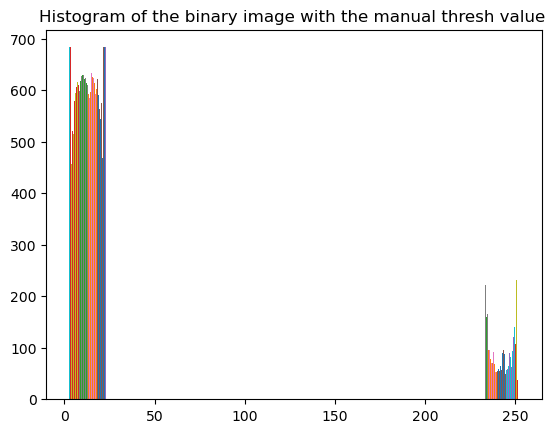

In [4]:
#creating the histogram of the binary image with the manual threshold value
histogram_fig=plot.figure(5)
hist1 = plot.hist(thresh_binary)
plot.title("Histogram of the binary image with the manual thresh value ")
plot.show()

In [5]:
histogram_fig.savefig('Histogram of the binary image with the manual thresh value.png')

The histogram reflects the pixel intensity distribution of the binary image derived from the given MRI scan of a brain. From the histogram, we can observe two distinct peaks corresponding to the two pixel values that define a binary image. The first peak, near the zero mark on the x-axis, represents the darker regions of the image (the background), which have been classified as non-significant areas after thresholding. The second, smaller peak near the 255 mark indicates the areas of interest (meaning the three depicted tumors) that are significantly brighter than the threshold value set at 100.

The majority of the image consists of background pixels with the regions of interest (tumors) occupying a smaller portion of the image. The sharpness of the peaks in the above histogram suggests that the thresholding was effective in creating a clear distinction between these two regions, which can be attributed to the prior noise reduction achieved through Gaussian blurring.

## B) Otsu's Method for Thresholding

In [6]:
#converting the RGB image to grayscale image
Grayscale_image = rgb2gray(img) # scikit image function

# Greyscale Image Normalization
normalized_grayscale_image = (Grayscale_image * 255).round().astype(np.uint8)

In [7]:
# Generate otsu threshold
threshold = threshold_otsu(normalized_grayscale_image)
# Apply threshold
Binary_image = normalized_grayscale_image > threshold
# Convert to integer
Binary_image=Binary_image.astype(int)


Text(0.5, 1.0, 'Binary Image (with otsu threshold)')

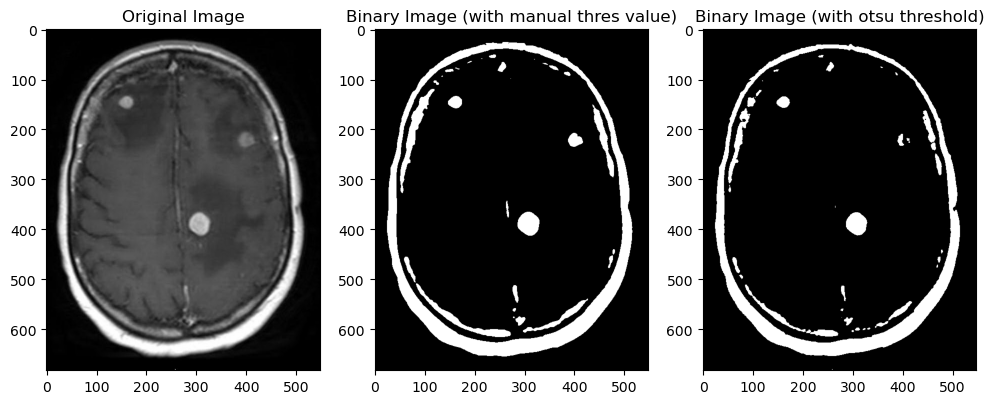

In [8]:
#Creating a figure to plot the necessary images
figure = plot.figure(2, figsize=(12,12))

subplot = figure.add_subplot(2,3,1)
plot.imshow(img, cmap='gray')
subplot.set_title('Original Image')

subplot = figure.add_subplot(2,3,2)
plot.imshow(thresh_binary, cmap="gray")
subplot.set_title('Binary Image (with manual thres value)')

subplot = figure.add_subplot(2,3,3)
plot.imshow(Binary_image, cmap="gray")
subplot.set_title('Binary Image (with otsu threshold)')

In [9]:
figure.savefig('Binary images comparison.png')

The manual threshold image seems to create a stronger contrast between the tumors and the surrounding tissue, which could potentially make the tumors stand out more. However, it also includes a lot of noise, as indicated by the small white spots throughout the brain area.

The Otsu threshold image is cleaner with less noise, but it seems to have a slightly lower contrast between the tumors and the surrounding brain tissue. The tumors are still visible but may not be as sharply defined as with the manual method (see the right tumor that is not as well depicted as the one in the manual threshold image).

Given that the  objective is making the three tumors more distinct, the choice between the two thresholding methods would be based on which image shows the tumors more clearly while minimizing other non-tumor regions. Therefore, the manual threshold might seem more suitable due to the contrast it provides, but it does require careful adjustment and possibly further post-processing to ensure that the tumors are accurately depicted without introducing too much noise. 


In [10]:
[Labeled_image,num_of_neighbors] = measure.label(thresh_binary,  connectivity=1,background=False,return_num=True) #Get labeled image on 4 neighbors

Group_connected_list = image_tool.measure.regionprops(Labeled_image)

List_of_Areas = []
List_of_Areas.append([d["area"] for d in Group_connected_list])

List_of_Areas = np.transpose(List_of_Areas)


Position_from_0_to_100 = [i for i, e in enumerate(List_of_Areas) if e > 500 and e < 550]
Position_from_0_to_100 = np.transpose(Position_from_0_to_100) + 1

Position_from_0_to_200 = [i for i, e in enumerate(List_of_Areas) if e > 550 and e < 990]
Position_from_0_to_200 = np.transpose(Position_from_0_to_200) + 1

Position_from_0_MAX = [i for i, e in enumerate(List_of_Areas) if e > 1600 and e < 1610 ]
Position_from_0_MAX = np.transpose(Position_from_0_MAX) + 1


Image_from_0_to_100 = []
Image_from_0_to_200 = []
Image_from_0_MAX = []

for i in range(len(Position_from_0_to_100)):
    Image_from_0_to_100.append(Labeled_image == Position_from_0_to_100[i])

for i in range(len(Position_from_0_to_200)):
    Image_from_0_to_200.append(Labeled_image == Position_from_0_to_200[i])

for i in range(len(Position_from_0_MAX)):
    Image_from_0_MAX.append(Labeled_image == Position_from_0_MAX[i])


for i in range(len(Position_from_0_to_100)):
    Image_from_0_to_100[i] = np.asarray(Image_from_0_to_100[i], dtype=np.int32)

for i in range(len(Position_from_0_to_200)):
    Image_from_0_to_200[i] = np.asarray(Image_from_0_to_200[i], dtype=np.int32)

for i in range(len(Position_from_0_MAX)):
    Image_from_0_MAX[i] = np.asarray(Image_from_0_MAX[i], dtype=np.int32)

In [11]:
[Labeled_image,num_of_neighbors] = measure.label(thresh_binary,  connectivity=1,background=False,return_num=True) #Get labeeled image on 4 neighbors

Group_connected_list = image_tool.measure.regionprops(Labeled_image)

List_of_Areas = []
List_of_Areas.append([d["area"] for d in Group_connected_list])

List_of_Areas = np.transpose(List_of_Areas)


Position_from_0_MAX2 = [i for i, e in enumerate(List_of_Areas) if e > 400 and e < 500 or e > 500 and e < 1000 or e > 1600 and e < 1610]
Position_from_0_MAX2 = np.transpose(Position_from_0_MAX2) + 1


Image_from_0_MAX2 = []


for i in range(len(Position_from_0_MAX2)):
    Image_from_0_MAX2.append(Labeled_image == Position_from_0_MAX2[i])

for i in range(len(Position_from_0_MAX2)):
    Image_from_0_MAX2[i] = np.asarray(Image_from_0_MAX2[i], dtype=np.int32)

In [12]:
Image_from_0_to_100 = sum(Image_from_0_to_100)
Image_from_0_to_200 = sum(Image_from_0_to_200)
Image_from_0_MAX = sum(Image_from_0_MAX)

Image_from_0_MAX2 = sum(Image_from_0_MAX2) #for plotting all the tumors 

Text(0.5, 1.0, 'All tumors')

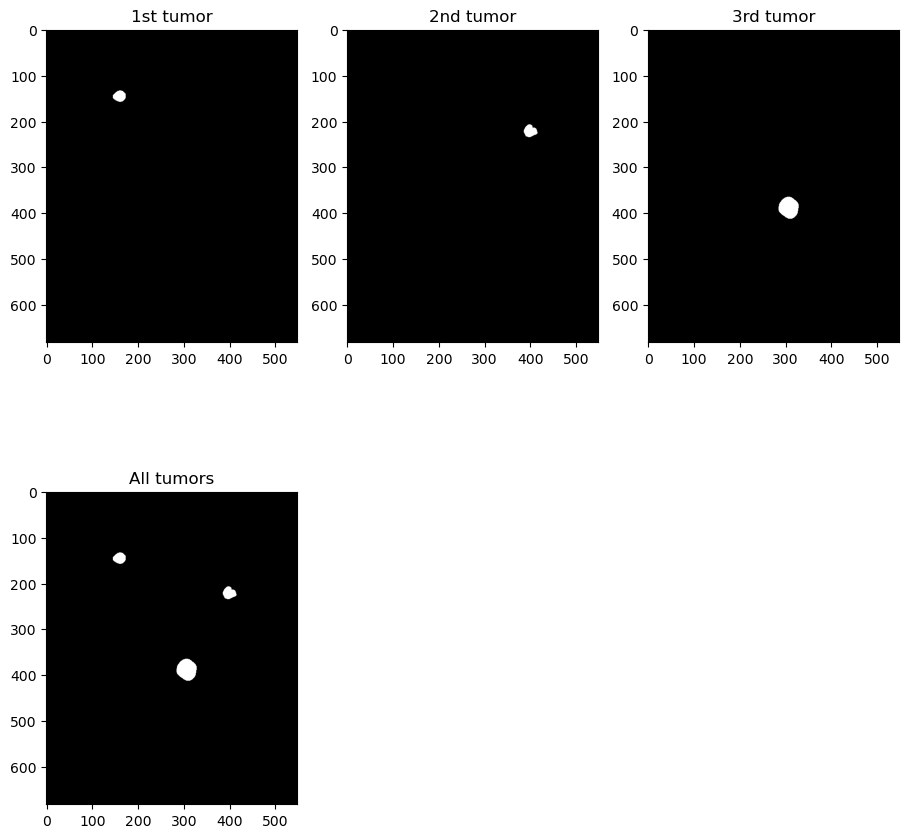

In [13]:
figure3 = plot.figure(3, figsize=(11,11))

subplot3 = figure3.add_subplot(2,3,1)
plot.imshow(Image_from_0_to_100, cmap='gray')
subplot3.set_title("1st tumor")

subplot3 = figure3.add_subplot(2,3,2)
plot.imshow(Image_from_0_to_200, cmap='gray')
subplot3.set_title("2nd tumor")

subplot3 = figure3.add_subplot(2,3,3)
plot.imshow(Image_from_0_MAX, cmap='gray')
subplot3.set_title("3rd tumor")

subplot3 = figure3.add_subplot(2,3,4)
plot.imshow(Image_from_0_MAX2, cmap='gray')
subplot3.set_title("All tumors")


In [14]:
figure3.savefig('Figure of tumors.png')

# Exploration with histograms of some properties of the areas (area, shape)

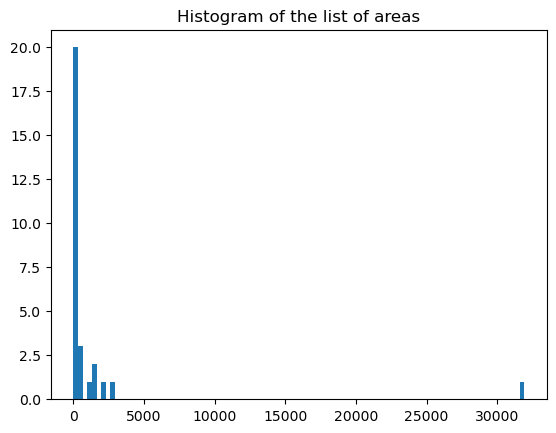

In [15]:
#creating the histogram of the list of areas 
histogram_fig1=plot.figure(6)
hist = plot.hist(List_of_Areas, bins='auto')
plot.title("Histogram of the list of areas")
plot.show()

In [16]:
histogram_fig1.savefig('List of the areas histogram.png')

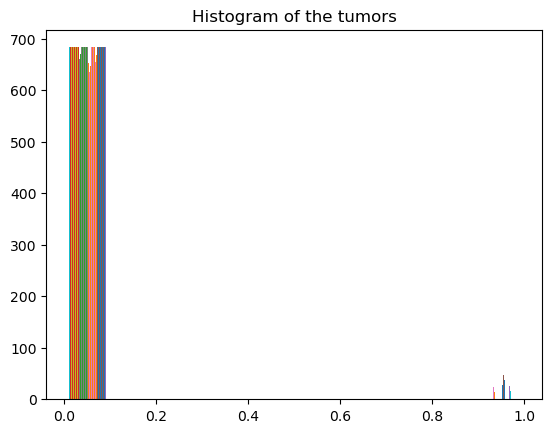

In [17]:
#creating the histogram of the tumors
histogram_fig3=plot.figure(3)
hist = plot.hist(Image_from_0_MAX2)
plot.title("Histogram of the tumors")
plot.show()

In [18]:
histogram_fig3.savefig('Tumors Histogram.png')

Finding the non-tumorous areas so that we can create a histogram and compare it with the tumorous area histogram. 

In [19]:
[Labeled_image,num_of_neighbors] = measure.label(thresh_binary,  connectivity=1,background=False,return_num=True) #Get labeeled image on 4 neighbors

Group_connected_list = image_tool.measure.regionprops(Labeled_image)

List_of_Areas = []
List_of_Areas.append([d["area"] for d in Group_connected_list])

List_of_Areas = np.transpose(List_of_Areas)


Position_from_0_MAX3 = [i for i, e in enumerate(List_of_Areas) if  e < 400 or e > 700 and e < 1600 or e > 1610 ]
Position_from_0_MAX3 = np.transpose(Position_from_0_MAX3) + 1


Image_from_0_MAX3 = []


for i in range(len(Position_from_0_MAX3)):
    Image_from_0_MAX3.append(Labeled_image == Position_from_0_MAX3[i])

for i in range(len(Position_from_0_MAX3)):
    Image_from_0_MAX3[i] = np.asarray(Image_from_0_MAX3[i], dtype=np.int32)

In [20]:
Image_from_0_MAX3 = sum(Image_from_0_MAX3) #for plotting all the tumors 

Text(0.5, 1.0, 'Non-tumor area')

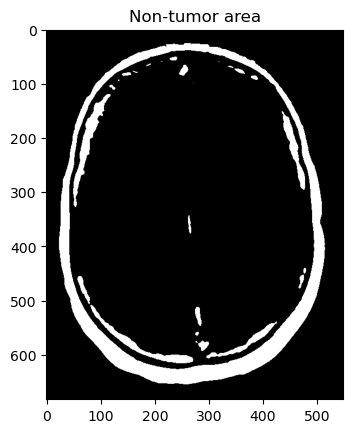

In [21]:
plot.imshow(Image_from_0_MAX3, cmap='gray')
plot.title("Non-tumor area")

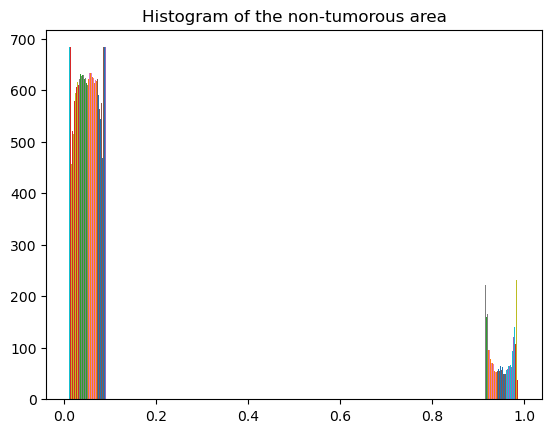

In [22]:
#creating the histogram of the non-tumorous area
histogram_fig13=plot.figure(13)
hist = plot.hist(Image_from_0_MAX3)
plot.title("Histogram of the non-tumorous area")
plot.show()

In [23]:
histogram_fig13.savefig('Non-tumorous histogram.png')

In a comparative analysis of the histograms representing tumor and non-tumorous tissue areas, a marked difference in data distribution is observed. The tumor tissue histogram exhibits a highly concentrated clustering of values near the 0.0 mark, indicative of homogeneity within the measured property of tumor areas. 

In contrast, the non-tumorous tissue histogram shows a wider spread of data points and multiple peaks, reflecting greater variability and heterogeneity in the non-tumorous tissue. These differences may highlight distinctive biological and histological characteristics between tumorous and non-tumorous tissues. 

In [24]:
#prints foe the area of each tumor 
print("Area of the first tumor (in pixels):", Image_from_0_to_100.sum())
print("Area of the second tumor (in pixels):", Image_from_0_to_200.sum())
print("Area of the third tumor (in pixels):", Image_from_0_MAX.sum())
print("Area of all the 3 tumors (in pixels):", Image_from_0_MAX2.sum())

Area of the first tumor (in pixels): 531
Area of the second tumor (in pixels): 585
Area of the third tumor (in pixels): 1605
Area of all the 3 tumors (in pixels): 2721


In [25]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


#coverting the original image to grayscale 
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
# blurring the gray image to remove any noise
blurred = cv2.GaussianBlur(gray, (7, 7), 0)

#applying the threshold (with manual value of 100)
ret, thresh_binary = cv2.threshold(blurred, 100, 255, cv2.THRESH_BINARY)

# Find contours from the binary image
contours, _ = cv2.findContours(thresh_binary, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Function to calculate shape descriptors
def calculate_shape_descriptors(contour):
    # Calculate the area and perimeter of the contour
    area = cv2.contourArea(contour)
    perimeter = cv2.arcLength(contour, True)
    
    # Calculate circularity, avoid division by zero
    circularity = (4 * np.pi * area) / (perimeter ** 2) if perimeter > 0 else 0
    
    # Calculate the aspect ratio using the bounding rectangle of the contour
    x, y, w, h = cv2.boundingRect(contour)
    aspect_ratio = w / float(h) if h > 0 else 0

    return circularity, aspect_ratio

# Lists to store the shape descriptors
circularities = []
aspect_ratios = []

# Calculate shape descriptors for each contour
for contour in contours:
    circularity, aspect_ratio = calculate_shape_descriptors(contour)
    circularities.append(circularity)
    aspect_ratios.append(aspect_ratio)


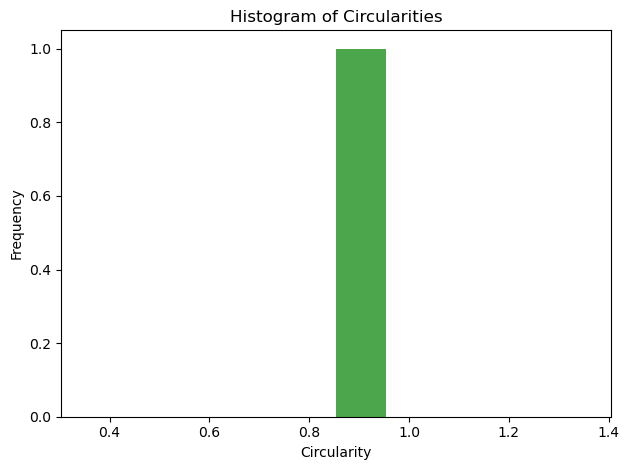

In [26]:
# Histogram for circularities
histogram_fig2=plot.figure(13)
hist = plot.hist(circularities, bins=10, color='green', alpha=0.7)
plot.title('Histogram of Circularities')
plot.xlabel('Circularity')
plot.ylabel('Frequency')
plot.tight_layout()
plot.show()

In [27]:
histogram_fig2.savefig('Histogram of Circularities.png')

Regarding the shape of the tumors, the histogram of circularities reflects the geometric properties of the detected tumors. This particular histogram presents a prominent peak with circularity values clustering around 1. This implies that the tumors detected within the brain exhibit a high degree of roundness, with shapes closely resembling perfect circles. Circularity is a shape metric that compares the area of a shape to its perimeter, with a value of 1 indicating a perfect circle. In the context of medical imaging, such a distribution indicates that the detected tumors are likely to be well-defined and isolated. It is also important to note the absence of lower circularity values, which suggests there are no elongated or irregularly shaped tumors in the image or that such shapes were not detected by the contouring algorithm.

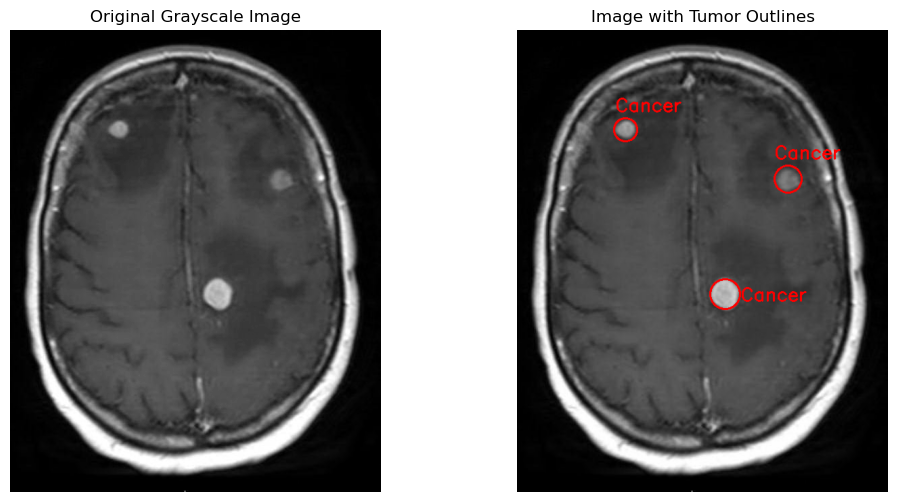

In [28]:
from matplotlib.patches import Circle
from matplotlib.colors import ListedColormap


# Create a custom colormap for red color
red_cmap = ListedColormap(['red'])

# Convert the grayscale image to a binary image (you might need to adjust the threshold)
_, binary_image2 = cv2.threshold(gray, 100, 255, cv2.THRESH_BINARY)

# Label the connected components in the binary image
labeled_image, num_of_labels = measure.label(binary_image2, connectivity=2, background=False, return_num=True)

# Calculate properties of labeled regions
connected_list = measure.regionprops(labeled_image)

# Create a copy of the original image to draw on
annotated_image = np.copy(gray)

# Manually specified bounding boxes for regions of interest
# Each tuple represents (minr, minc, maxr, maxc)
bounding_boxes = [
    (130, 145, 165, 175),   #(y1, x1, y2, x2)  
    (200, 380, 240, 420),   #(y3, x3, y4, x4) 
    (415, 330, 365, 285)   # (y5, x5, y6, x6) 
]


# Convert the grayscale image to a color image 
if len(annotated_image.shape) == 2 or annotated_image.shape[2] == 1:  # Grayscale
    annotated_image = cv2.cvtColor(annotated_image, cv2.COLOR_GRAY2BGR)
    
# Function to safely calculate the radius
def safe_radius(min_val, max_val):
    return max(min(max_val - min_val, max_val - min_val) // 2, 0)

# Function to calculate a larger radius for the third region
def larger_radius(min_val, max_val, increase_factor):
    return max(safe_radius(min_val, max_val) + increase_factor, 0)

# First Region
center_x1 = (145 + 175) // 2
center_y1 = (130 + 165) // 2
radius1 = safe_radius(130, 165)
cv2.circle(annotated_image, (center_x1, center_y1), radius1, (255, 0, 0), 2)
cv2.putText(annotated_image, 'Cancer', (145, 130 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

# Second Region
center_x2 = (380 + 420) // 2
center_y2 = (200 + 240) // 2
radius2 = safe_radius(200, 240)
cv2.circle(annotated_image, (center_x2, center_y2), radius2, (255, 0, 0), 2)
cv2.putText(annotated_image, 'Cancer', (380, 200 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)

# Third Region
center_x3 = (330 + 285) // 2
center_y3 = (415 + 365) // 2
radius3 = larger_radius(415, 365, 22)  # Increase the radius by 20 units
cv2.circle(annotated_image, (center_x3, center_y3), radius3, (255, 0, 0), 2)  # Red circle
cv2.putText(annotated_image, 'Cancer', (330, 415 - 15), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 0, 0), 2)  


# Display the original and modified images
figure10 = plot.figure(figsize=(12, 6))

# Original image
subplot10 = figure10.add_subplot(1, 2, 1)
plot.imshow(gray, cmap='gray')
plot.title('Original Grayscale Image')
plot.axis('off')

# Annotated image
subplot10 = figure10.add_subplot(1, 2, 2)
plot.imshow(annotated_image, cmap='gray')
plot.title('Image with Tumor Outlines')
plot.axis('off')

plot.show()


In [29]:
figure10.savefig('Histogram of Circularities.png')

Regarding the above figure, on the left, we have the grayscale image of the mri while on the right, we have the image that displays the tumor outlines. In more detail, three circular outlines, presumably in red, are drawn around areas identified as tumors. The word "Cancer" is annotated adjacent to each outlined region, which serves to label these areas clearly for the viewer.

In [30]:
from skimage.draw import disk
from skimage.morphology import erosion, dilation, closing, opening, area_closing, area_opening
import skimage.morphology
from skimage import data, morphology
from skimage.morphology import erosion
import scipy.ndimage

#Morphological Masks
Mask_Diamond = skimage.morphology.diamond(3)
Mask_Diamond = np.asarray(Mask_Diamond, dtype=np.int32)

Mask_Disk = skimage.morphology.disk(3)
Mask_Disk = np.asarray(Mask_Disk, dtype=np.int32)

Mask_Square = skimage.morphology.square(3)  # OR Mask_square=np.ones((3,3))
Mask_Square = np.asarray(Mask_Square, dtype=np.int32)

Mask_Rectangle = skimage.morphology.rectangle(3, 5)  # OR Mask_Rectangle=np.ones((3,5))
Mask_Rectangle = np.asarray(Mask_Rectangle, dtype=np.int32)

Mask_Crucifix = scipy.ndimage.generate_binary_structure(2, 1)
Mask_Crucifix = np.asarray(Mask_Crucifix, dtype=np.int32)

Mask_Octagon = skimage.morphology.octagon(3, 5)
Mask_Octagon = np.asarray(Mask_Octagon, dtype=np.int32)


In [31]:
#Applying erosion in the binary image with different masks 

erosion_maskDisk = erosion(thresh_binary, Mask_Disk)
erosion_maskDiamond = erosion(thresh_binary, Mask_Diamond)
erosion_Mask_Square = erosion(thresh_binary, Mask_Square)
erosion_Mask_Rectangle = erosion(thresh_binary, Mask_Rectangle)
erosion_Mask_Crucifix = erosion(thresh_binary, Mask_Crucifix)
erosion_Mask_Octagon = erosion(thresh_binary, Mask_Octagon)

In [32]:
#Applying dilation in the binary image with different masks 

dilation_maskDisk = dilation(thresh_binary, Mask_Disk)
dilation_maskDiamond = dilation(thresh_binary, Mask_Rectangle)
dilation_Mask_Square = dilation(thresh_binary, Mask_Square)
dilation_Mask_Rectangle = dilation(thresh_binary, Mask_Rectangle)
dilation_Mask_Crucifix = dilation(thresh_binary, Mask_Crucifix)
dilation_Mask_Octagon = dilation(thresh_binary, Mask_Octagon)

In [33]:
#Applying opening in the binary image with different masks 

opened_MaskDisk = morphology.opening(thresh_binary, Mask_Disk)
opened_MaskDiamond = morphology.opening(thresh_binary, Mask_Diamond)
opened_Mask_Square = morphology.opening(thresh_binary, Mask_Square)
opened_Mask_Rectangle = morphology.opening(thresh_binary, Mask_Rectangle)
opened_Mask_Crucifix = morphology.opening(thresh_binary, Mask_Crucifix)
opened_Mask_Octagon = morphology.opening(thresh_binary, Mask_Octagon)


In [34]:
#Applying closing in the binary image with different masks 

closed_MaskDisk = morphology.closing(thresh_binary, Mask_Disk)
closed_MaskDiamond = morphology.closing(thresh_binary, Mask_Diamond)
closed_Mask_Square = morphology.closing(thresh_binary, Mask_Square) 
closed_Mask_Rectangle = morphology.closing(thresh_binary, Mask_Rectangle) 
closed_Mask_Crucifix = morphology.closing(thresh_binary, Mask_Crucifix) 
closed_Mask_Octagon = morphology.closing(thresh_binary, Mask_Octagon)


## The plots below are only for comparison between the different types of masks used in the erosion, dilation, opening and closing of the binary image. 

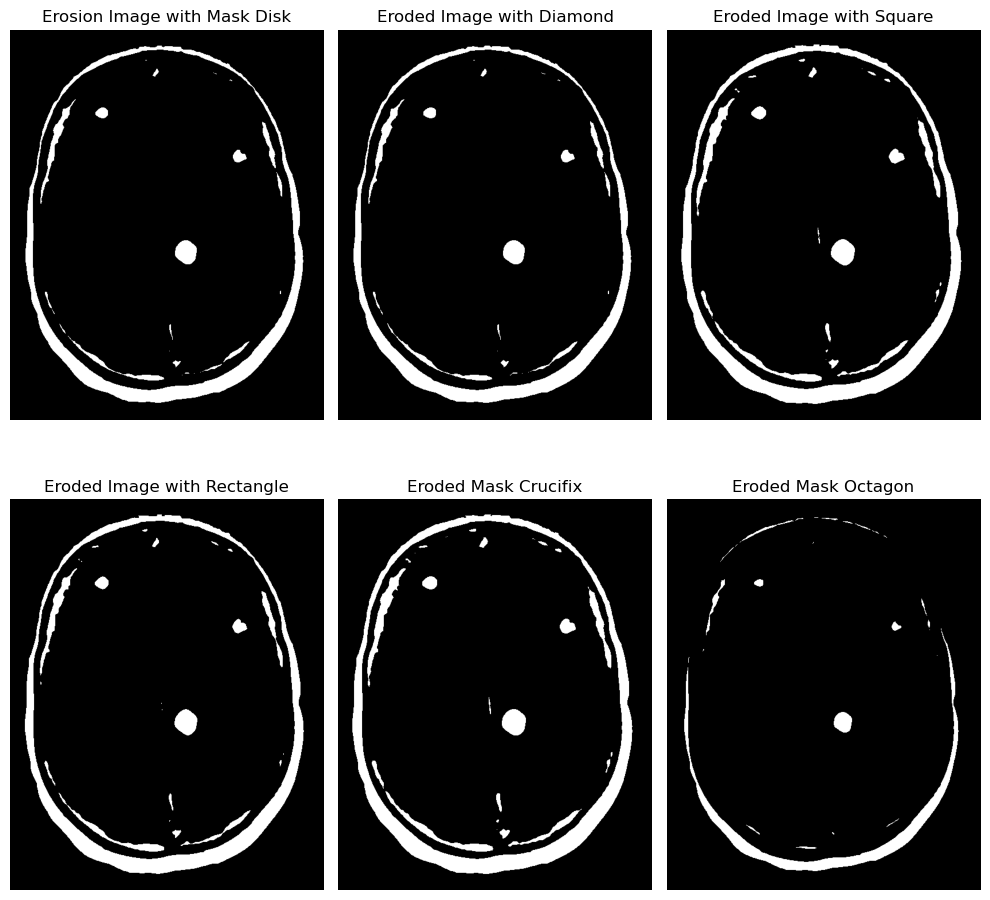

In [35]:
import matplotlib.pyplot as plt

eroded_figure = plt.figure(figsize=(10, 10))  

plt.subplot(2, 3, 1)
plt.imshow(erosion_maskDisk, cmap='gray')
plt.title('Erosion Image with Mask Disk')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(erosion_maskDiamond, cmap='gray')
plt.title('Eroded Image with Diamond')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(erosion_Mask_Square, cmap='gray')
plt.title('Eroded Image with Square')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(erosion_Mask_Rectangle, cmap='gray')
plt.title('Eroded Image with Rectangle')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(erosion_Mask_Crucifix, cmap='gray')
plt.title('Eroded Mask Crucifix')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(erosion_Mask_Octagon, cmap='gray')
plt.title('Eroded Mask Octagon')
plt.axis('off')

plt.tight_layout()
plt.show()


Regarding the erosion, six distinct erosion masks have been utilized, each demonstrating varying degrees of effectiveness in isolating the three targeted tumors. Comparing the different eroted images with the original binary image we observe that the crucifix mask has the best similarity to the binary reference image in terms of preserving the tumors' shape and size. Therefore, the crucifix mask provides the best results for highlighting the tumors when comparing to the provided binary image.

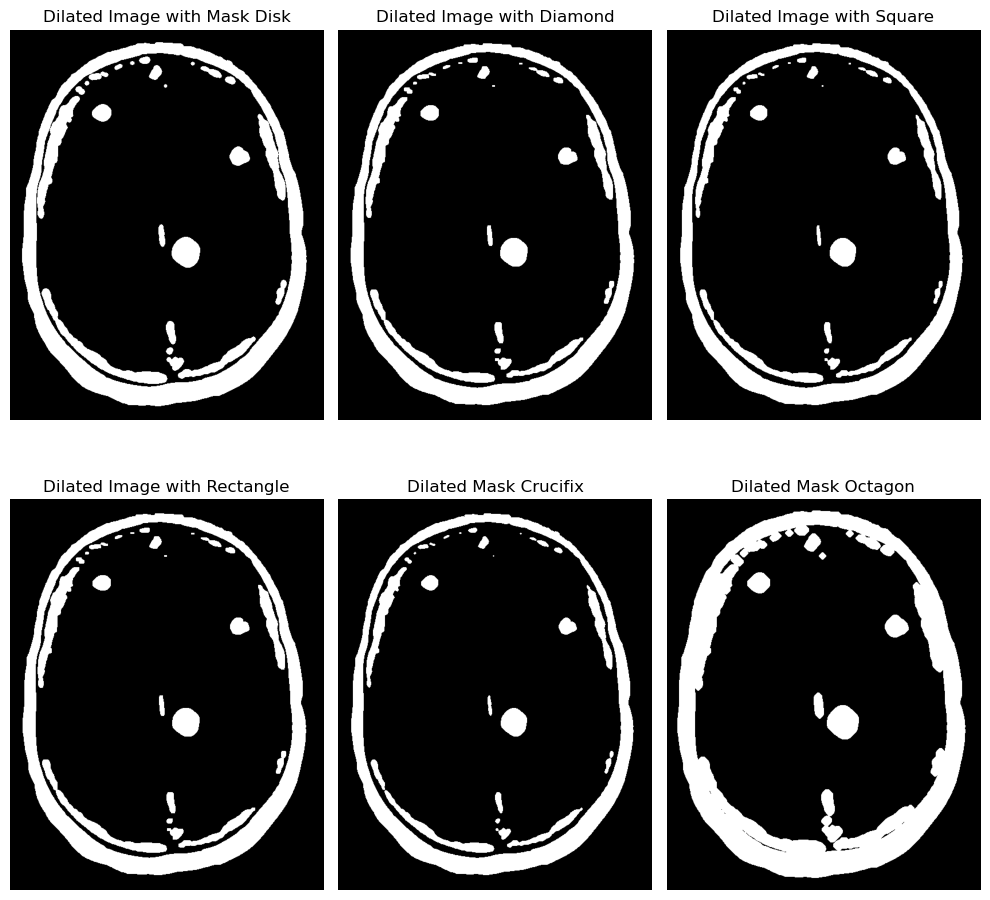

In [36]:
import matplotlib.pyplot as plt

dilation_figure = plt.figure(figsize=(10, 10)) 

plt.subplot(2, 3, 1)
plt.imshow(dilation_maskDisk, cmap='gray')
plt.title('Dilated Image with Mask Disk')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(dilation_maskDiamond, cmap='gray')
plt.title('Dilated Image with Diamond')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(dilation_Mask_Square, cmap='gray')
plt.title('Dilated Image with Square')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(dilation_Mask_Rectangle, cmap='gray')
plt.title('Dilated Image with Rectangle')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(dilation_Mask_Crucifix, cmap='gray')
plt.title('Dilated Mask Crucifix')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(dilation_Mask_Octagon, cmap='gray')
plt.title('Dilated Mask Octagon')
plt.axis('off')

plt.tight_layout()
plt.show()


In the "Dilated Image with Mask Disk," the edges of the object appear smoother and thicker due to the disk's uniform expansion effect. The "Dilated Image with Diamond" and "Dilated Image with Square" indicate the use of diamond and square structuring elements, which augment the object's boundaries in accord with their shapes, leading to angular extensions and a more pronounced increase in area.

The "Dilated Image with Rectangle" suggests an anisotropic expansion, likely emphasizing growth in particular orientations in line with the rectangle's longer axis. The "Dilated Mask Crucifix" shows a pattern of dilation that extends prominently in the cardinal directions, reflecting the shape of the crucifix structuring element. Lastly, the "Dilated Mask Octagon" results in a bulkier outline with rounded corners, staying intermediate between the disk and the more angular diamond and square effects. 

Regarding the dilation, the Dilated Mask Crucifix gives as good results compared to the binary image. 

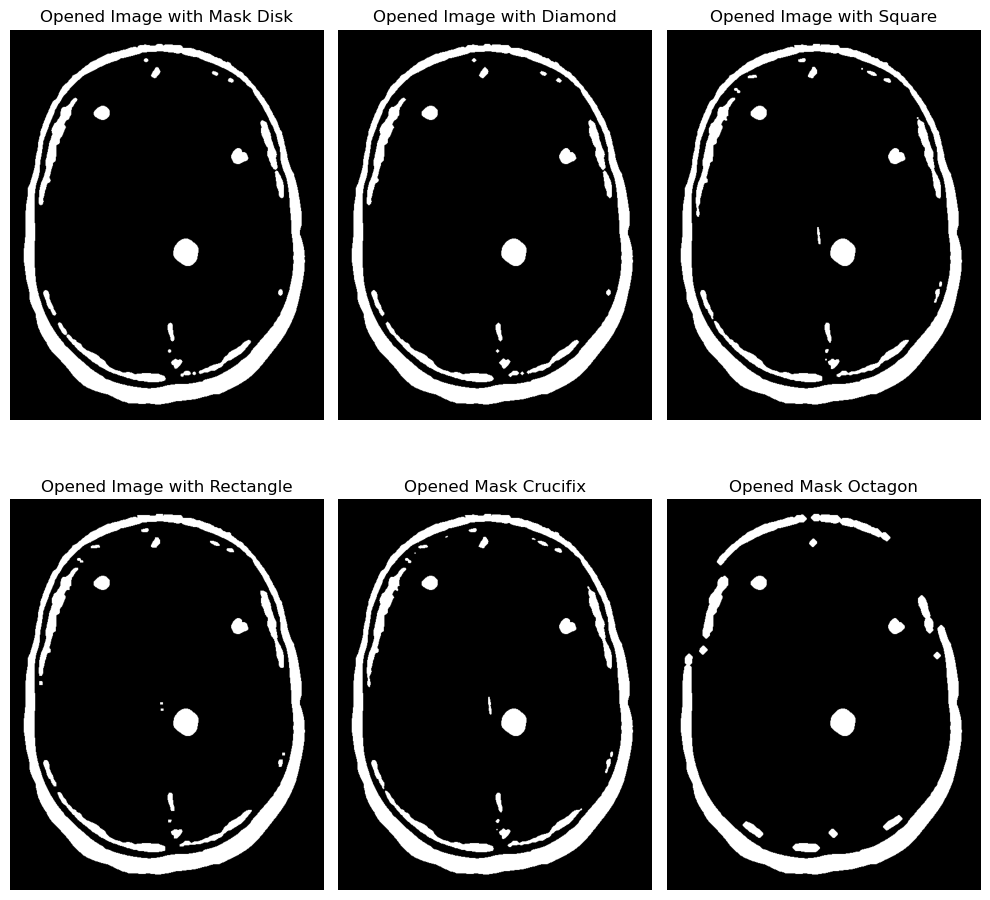

In [37]:
import matplotlib.pyplot as plt

opening_figure = plt.figure(figsize=(10, 10))  

plt.subplot(2, 3, 1)
plt.imshow(opened_MaskDisk, cmap='gray')
plt.title('Opened Image with Mask Disk')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(opened_MaskDiamond, cmap='gray')
plt.title('Opened Image with Diamond')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(opened_Mask_Square, cmap='gray')
plt.title('Opened Image with Square')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(opened_Mask_Rectangle, cmap='gray')
plt.title('Opened Image with Rectangle')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(opened_Mask_Crucifix, cmap='gray')
plt.title('Opened Mask Crucifix')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(opened_Mask_Octagon, cmap='gray')
plt.title('Opened Mask Octagon')
plt.axis('off')

plt.tight_layout()
plt.show()


The "Opened Image with Mask Disk" seems to smooth edges and remove small objects due to the erosion followed by dilation. Similarly does the "Opened Image with Diamond" and "Opened Image with Square". 

The "Opened Image with Rectangle" demonstrates a more directional opening, likely targeting specific orientations within the image. Regarding the "Opened Mask Crucifix", the crucifix shape might be emphasizing vertical and horizontal information keeping the image close enough to the original binary image, whereas the octagon in the "Opened Mask Octagon" appears to retain more edge detail than the disk, but less than the diamond and square. 

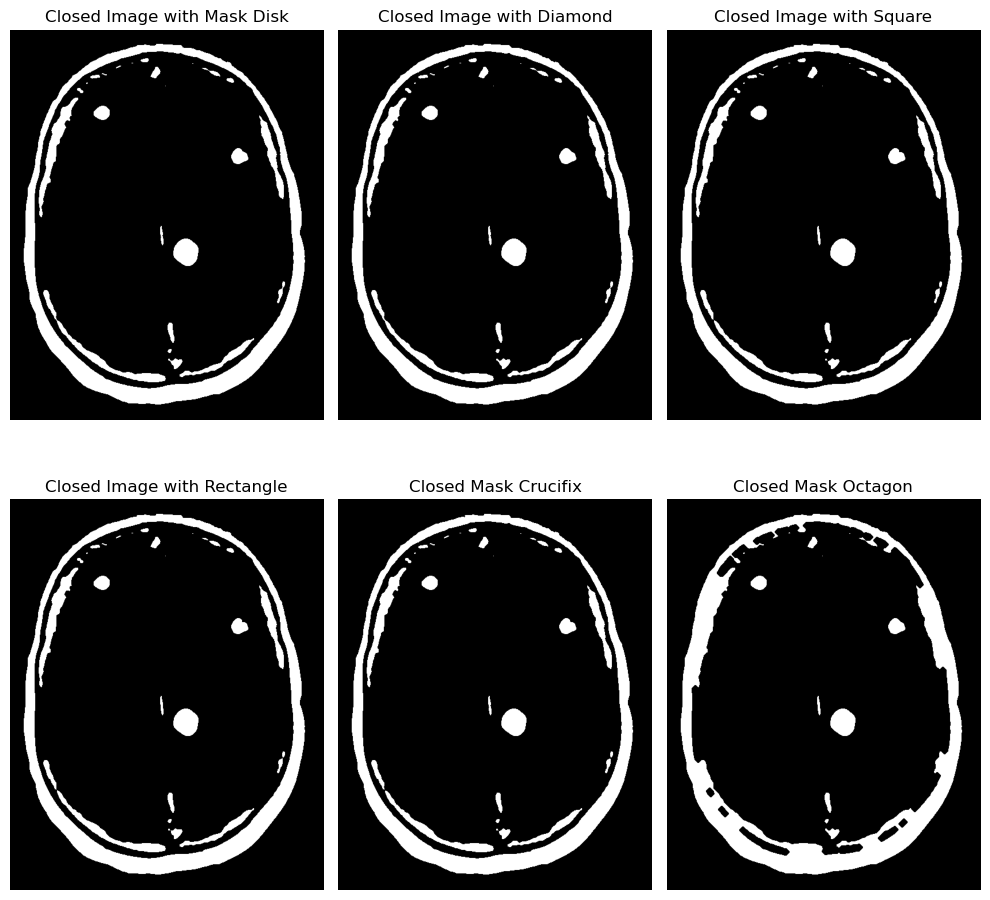

In [38]:
import matplotlib.pyplot as plt

closing_figure = plt.figure(figsize=(10, 10)) 

plt.subplot(2, 3, 1)
plt.imshow(closed_MaskDisk, cmap='gray')
plt.title('Closed Image with Mask Disk')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(closed_MaskDiamond, cmap='gray')
plt.title('Closed Image with Diamond')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(closed_Mask_Square, cmap='gray')
plt.title('Closed Image with Square')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(closed_Mask_Rectangle, cmap='gray')
plt.title('Closed Image with Rectangle')
plt.axis('off')

plt.subplot(2, 3, 5)
plt.imshow(closed_Mask_Crucifix, cmap='gray')
plt.title('Closed Mask Crucifix')
plt.axis('off')

plt.subplot(2, 3, 6)
plt.imshow(closed_Mask_Octagon, cmap='gray')
plt.title('Closed Mask Octagon')
plt.axis('off')

plt.tight_layout()
plt.show()


The "Closed Image with Mask Disk" indicates smoothed the object's outline and filled in small holes and gaps, creating a more uniform and rounded appearance. Similarly, the "Closed Image with Diamond" and "Closed Image with Square" show the effects of their respective structuring elements, leading to slight protrusions in the object's outline that reflect the shapes of the diamonds and squares.

In the "Closed Image with Rectangle," the closing effect seems to be elongated in the direction parallel to the longer sides of the rectangle, suggesting a more anisotropic closing. The "Closed Mask Crucifix" demonstrates a distinctive cross-shaped influence on the object's morphology, particularly noticeable in the way small gaps and holes are filled in. Finally, the "Closed Mask Octagon" presents an intermediate effect between the rounded disk and the more angular diamond and square, with octagonal edges softened and small defects within the object's boundary filled in. 

Each resulting image from the closing process shows the filling in of small holes and the bridging of narrow breaks or gaps.

Each mask has different effects on the image process. The choice of mask depends on the specific shapes and sizes of the structures that need to be preserved or removed. For highlighting tumors in an MRI image, the mask that best preserves the size, shape, and edges of the tumors while removing other structures is generally preferred. The goal of each mask is to enhance the contrast between the tumors and the surrounding tissue, and the choice of mask is crucial as it impacts the clarity and visibility of the tumors for subsequent analysis. Each mask's performance must be evaluated based on how well it aids in the accurate detection and diagnosis of the tumors present in the MRI image.

Keeping in mind all of the above, we get the best results with the use of the crucifix mask especially in the erosion and dilation process, where the results are more comparable with the use of the different masks. 

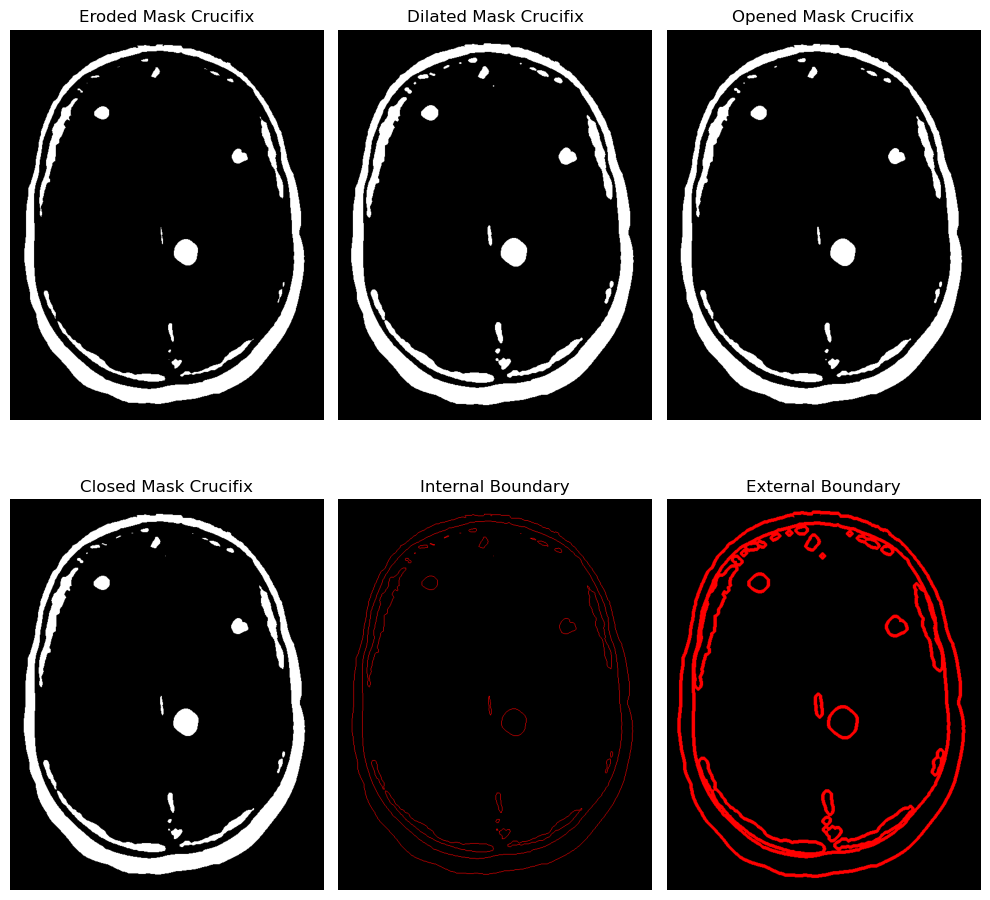

In [39]:
import cv2
import matplotlib.pyplot as plt

def highlight_red_contours(gray, mask):
    colored = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
    colored[mask != 0] = [255, 0, 0]  #RGB 
    return colored

internal_boundary = thresh_binary ^ erosion_Mask_Crucifix
external_boundary = dilation_Mask_Octagon ^ thresh_binary

boundaries_figure = plt.figure(figsize=(10, 10))  

plt.subplot(2, 3, 1)
plt.imshow(erosion_Mask_Crucifix, cmap='gray')
plt.title('Eroded Mask Crucifix')
plt.axis('off')

plt.subplot(2, 3, 2)
plt.imshow(dilation_Mask_Crucifix, cmap='gray')
plt.title('Dilated Mask Crucifix')
plt.axis('off')

plt.subplot(2, 3, 3)
plt.imshow(opened_Mask_Crucifix, cmap='gray')
plt.title('Opened Mask Crucifix')
plt.axis('off')

plt.subplot(2, 3, 4)
plt.imshow(closed_Mask_Crucifix, cmap='gray')
plt.title('Closed Mask Crucifix')
plt.axis('off')

plt.subplot(2, 3, 5)
highlighted_internal_boundary = highlight_red(internal_boundary, internal_boundary)
plt.imshow(highlighted_internal_boundary)
plt.title('Internal Boundary')
plt.axis('off')

plt.subplot(2, 3, 6)
highlighted_external_boundary = highlight_red(external_boundary, external_boundary)
plt.imshow(highlighted_external_boundary)
plt.title('External Boundary')
plt.axis('off')

plt.tight_layout()
plt.show()


The internal boundary extraction shows contours that closely follow the inner edges of the object, capturing the nuances and irregularities within the object's silhouette. These inner contours are particularly useful for identifying features such as holes and indentations. On the other hand, the external boundary image depicts contours that are placed along the outer edges of the object. This external delineation is more complete, emphasizing the overall shape and boundary of the object, and includes minor protrusions and recesses in the object's outer perimeter.

Both boundary types are critical for different aspects of image analysis: internal boundaries for understanding the structural integrity and features within the object, and external boundaries for assessing the object's overall form and interaction with its surroundings. The clarity and completeness of the boundary lines in both images suggest a high-contrast and precise segmentation process, which is essential for subsequent image processing tasks such as object recognition (for example in our case the tumors), shape analysis, or feature extraction.